<a href="https://colab.research.google.com/github/lnrdmnc/Quantum-Enhanced-Detection-Mechanisms-for-Mobile-Network-Security/blob/main/Mobile_QS_Emulation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Quantum Sensing Emulation — **Mobile Networks Only** (Python)

This notebook contains **Python-only** demos for mobile networks, emulating the *effects* of quantum sensing (QS) — higher sensitivity and better timing stability — on detection tasks relevant to 4G/5G/6G.

**Demos**
1. RF spectrum anomaly (rogue gNB / fake SSB tone).
2. Jamming detection and type hints (tone vs barrage) using spectrogram features.
3. Timing/GNSS/PTP spoofing detection with a simple Kalman filter (QS = better clock).
4. RACH preamble detection improvement via correlation SNR.

> Libraries: NumPy + Matplotlib only (no internet, no extra deps).


In [1]:

import numpy as np
import matplotlib.pyplot as plt

def periodogram(x, fs):
    X = np.fft.rfft(x * np.hanning(len(x)))
    Pxx = (np.abs(X)**2) / (fs * len(x))
    f = np.fft.rfftfreq(len(x), 1/fs)
    return f, 10*np.log10(Pxx + 1e-20)

def spectrogram_matrix(x, fs, nperseg=1024, noverlap=512):
    step = nperseg - noverlap
    win = np.hanning(nperseg)
    frames = 1 + (len(x) - nperseg) // step
    S = []
    for i in range(frames):
        seg = x[i*step : i*step+nperseg]
        X = np.fft.rfft(seg * win)
        S.append(20*np.log10(np.abs(X)+1e-12))
    S = np.array(S).T
    freqs = np.fft.rfftfreq(nperseg, 1/fs)
    times = np.arange(frames) * (step/fs)
    return freqs, times, S

def rolling_zscore(y, w):
    mu = np.convolve(y, np.ones(w)/w, mode='same')
    sigma = np.sqrt(np.convolve((y-mu)**2, np.ones(w)/w, mode='same') + 1e-6)
    return (y - mu) / (sigma + 1e-9)



## 1) RF Spectrum Anomaly — Rogue gNB / Fake SSB Tone

We synthesize three legitimate carriers plus a **weak rogue pilot**. QS is emulated by reducing measurement noise.


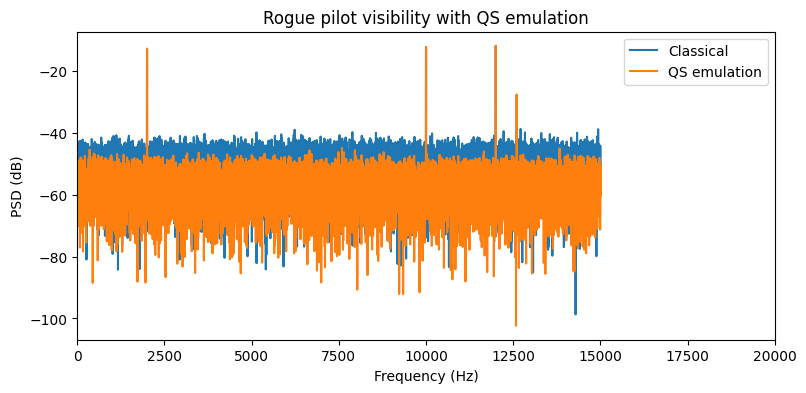

Peaks classical (Hz,dB): [(np.float64(2000.4), np.float64(-12.9)), (np.float64(10000.3), np.float64(-12.3)), (np.float64(11999.8), np.float64(-12.0))]
Peaks QS (Hz,dB):        [(np.float64(2000.4), np.float64(-12.8)), (np.float64(10000.3), np.float64(-12.3)), (np.float64(11999.8), np.float64(-11.8))]


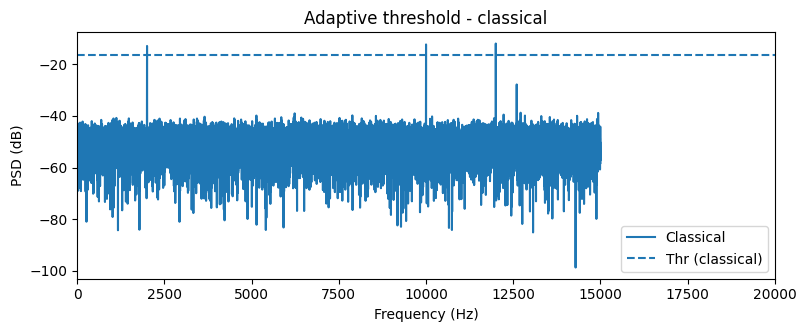

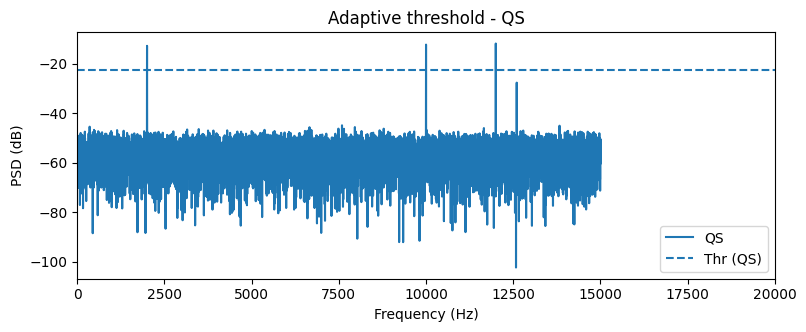

In [2]:

np.random.seed(42)
fs = 30e3
N = 2**15
t = np.arange(N)/fs

carriers = [2e3, 10e3, 18e3]
rogue_f = 12.6e3
rogue_amp = 0.18

signal = sum(np.cos(2*np.pi*f*t) for f in carriers)
signal += rogue_amp*np.cos(2*np.pi*rogue_f*t)  # attack

# Classical vs QS noise
sigma = 1.0
qs_gain_db = 6.0    # tweak this to see effect
rho = 10**(qs_gain_db/20)

x_classical = signal + np.random.normal(0, sigma, size=N)
x_qs = signal + np.random.normal(0, sigma/rho, size=N)

f, P_c = periodogram(x_classical, fs)
_, P_q = periodogram(x_qs, fs)

plt.figure(figsize=(9,4))
plt.plot(f, P_c, label="Classical")
plt.plot(f, P_q, label="QS emulation")
plt.xlim(0, 20e3)
plt.xlabel("Frequency (Hz)"); plt.ylabel("PSD (dB)")
plt.title("Rogue pilot visibility with QS emulation")
plt.legend(); plt.show()

# Simple detector: peak above adaptive threshold
def detect_peaks(P, f, k=6, min_sep=200):
    med = np.median(P); std = np.std(P - med); thr = med + k*std
    peaks = []
    last = -1e9
    for i in range(1, len(P)-1):
        if P[i] > P[i-1] and P[i] > P[i+1] and P[i] > thr:
            if f[i] - last >= min_sep:
                peaks.append((f[i], P[i])); last = f[i]
    return peaks, thr

peaks_c, thr_c = detect_peaks(P_c, f)
peaks_q, thr_q = detect_peaks(P_q, f)

print("Peaks classical (Hz,dB):", [(round(ff,1), round(pp,1)) for ff,pp in peaks_c])
print("Peaks QS (Hz,dB):       ", [(round(ff,1), round(pp,1)) for ff,pp in peaks_q])

# Mark threshold
plt.figure(figsize=(9,3.2))
plt.plot(f, P_c, label="Classical")
plt.axhline(thr_c, linestyle="--", label="Thr (classical)")
plt.xlim(0, 20e3); plt.xlabel("Frequency (Hz)"); plt.ylabel("PSD (dB)")
plt.title("Adaptive threshold - classical")
plt.legend(); plt.show()

plt.figure(figsize=(9,3.2))
plt.plot(f, P_q, label="QS")
plt.axhline(thr_q, linestyle="--", label="Thr (QS)")
plt.xlim(0, 20e3); plt.xlabel("Frequency (Hz)"); plt.ylabel("PSD (dB)")
plt.title("Adaptive threshold - QS")
plt.legend(); plt.show()



## 2) Jamming Detection & Type Hints — Tone vs Barrage

We simulate **barrage** (wideband) and **tone** (narrowband) jammers.  
Two lightweight features flag and hint the type:
- **BW energy ratio**: energy in top-k bins vs total (tone jammers compress energy).
- **Spectral kurtosis**: higher for tone jammers.

QS acts again as measurement-noise reduction.


barrage (C): BW-ratio=0.307, kurtosis=42436.06
barrage (QS): BW-ratio=0.324, kurtosis=42593.60
tone (C): BW-ratio=0.921, kurtosis=35851.83
tone (QS): BW-ratio=0.979, kurtosis=35781.69


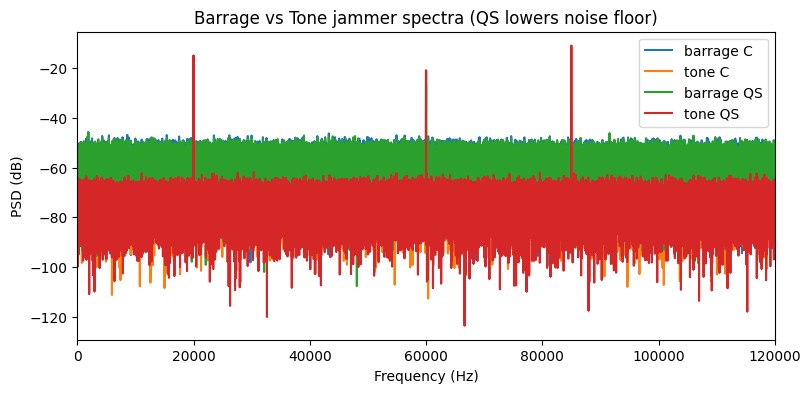

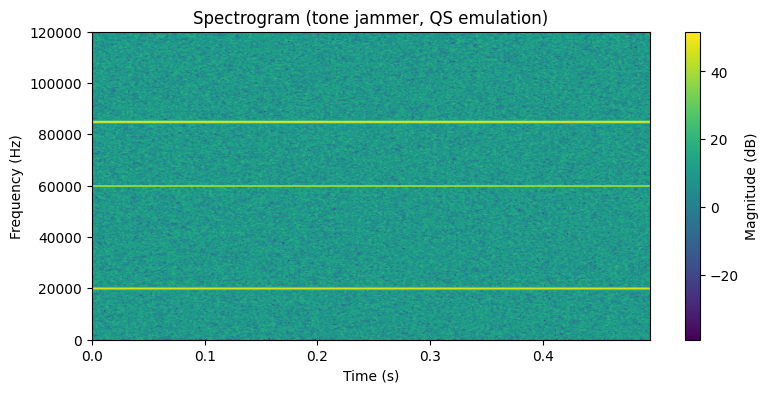

In [3]:

fs = 240e3; T = 0.5; N = int(fs*T)
t = np.arange(N)/fs
payload = np.cos(2*np.pi*20e3*t) + 0.5*np.cos(2*np.pi*60e3*t)

def make_jam(kind="barrage", snr_db=-5):
    if kind=="barrage":
        jam = np.random.normal(0, 1.0, size=N)  # wide noise
    else:
        jf = 85e3
        jam = 3.0*np.cos(2*np.pi*jf*t)          # strong narrow tone
    # scale to SNR
    s_power = np.mean(payload**2)
    j_power = np.mean(jam**2)
    alpha = np.sqrt(s_power * 10**(-snr_db/10) / j_power)
    return payload + alpha*jam

x_barr = make_jam("barrage", snr_db=-3)
x_tone = make_jam("tone", snr_db=-3)

# Add measurement noise: classical vs QS
sigma = 0.4; rho = 10**(6/20)
x_barr_c = x_barr + np.random.normal(0, sigma, size=N)
x_barr_q = x_barr + np.random.normal(0, sigma/rho, size=N)
x_tone_c = x_tone + np.random.normal(0, sigma, size=N)
x_tone_q = x_tone + np.random.normal(0, sigma/rho, size=N)

def features(x):
    f, P = periodogram(x, fs)
    P_lin = 10**(P/10)
    idx = np.argsort(P_lin)[-20:]
    bw_ratio = P_lin[idx].sum()/P_lin.sum()
    kurt = np.mean(((P_lin - P_lin.mean())/ (P_lin.std()+1e-12))**4)
    return bw_ratio, kurt, f, P

for name, sig in [("barrage (C)", x_barr_c), ("barrage (QS)", x_barr_q),
                  ("tone (C)", x_tone_c), ("tone (QS)", x_tone_q)]:
    bw, ku, fP, PP = features(sig)
    print(f"{name}: BW-ratio={bw:.3f}, kurtosis={ku:.2f}")

# Visualize spectra
plt.figure(figsize=(9,4))
for sig, lab in [(x_barr_c,"barrage C"), (x_tone_c,"tone C"),
                 (x_barr_q,"barrage QS"), (x_tone_q,"tone QS")]:
    f, P = periodogram(sig, fs)
    plt.plot(f, P, label=lab)
plt.xlim(0, 120e3); plt.xlabel("Frequency (Hz)"); plt.ylabel("PSD (dB)")
plt.title("Barrage vs Tone jammer spectra (QS lowers noise floor)")
plt.legend(); plt.show()

# Spectrogram for tone jammer clarity
freqs, times, S_tone = spectrogram_matrix(x_tone_q, fs, nperseg=1024, noverlap=768)
plt.figure(figsize=(9,4))
plt.imshow(S_tone, aspect='auto', origin='lower',
           extent=[times[0], times[-1], freqs[0], freqs[-1]])
plt.colorbar(label="Magnitude (dB)")
plt.xlabel("Time (s)"); plt.ylabel("Frequency (Hz)")
plt.title("Spectrogram (tone jammer, QS emulation)")
plt.show()



## 3) Timing / GNSS / PTP Spoofing Detection — Kalman Filter

We model a clock phase \(\phi\) and frequency offset \(\dot\phi\). Spoofing injects a small step in phase.  
QS is emulated as **lower measurement noise** (better local oscillator). We flag innovations that exceed a threshold.


/tmp/ipython-input-1514838749.py:44: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  xs.append(x.copy()); innov.append(float(y/np.sqrt(S)))


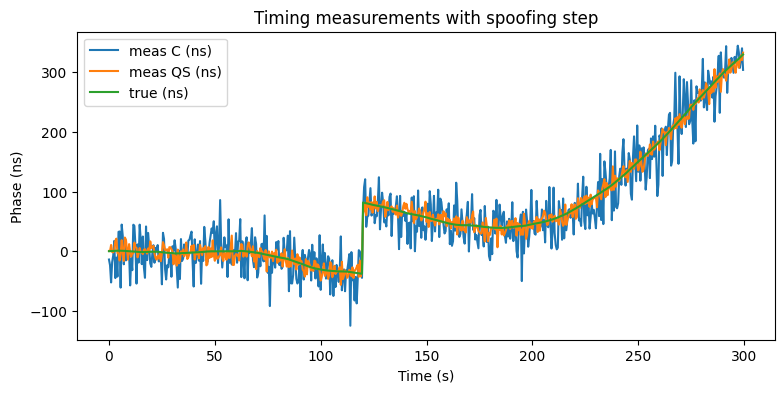

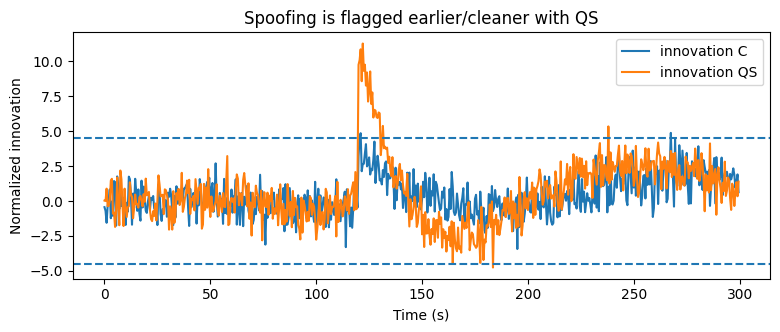

Max innovation (C, QS): 4.880022986655497 11.279966018467595


In [4]:

np.random.seed(7)
T = 300; dt = 0.5; steps = int(T/dt)

# True process
phi = 0.0; dphi = 0.0
phi_true = []; z_meas_c = []; z_meas_q = []
meas_std_c = 30e-9        # 30 ns classical
meas_std_q = 10e-9        # 10 ns with QS-grade clock

spoof_step_time = 120.0   # seconds
spoof_step = 120e-9       # 120 ns bias injection

for k in range(steps):
    # random walk frequency noise
    dphi += np.random.normal(0, 0.1e-9)  # frequency wander (ns/s)
    phi += dphi*dt
    tnow = k*dt
    if abs(tnow - spoof_step_time) < 1e-9 or tnow>spoof_step_time and tnow<spoof_step_time+dt:
        phi += spoof_step
    phi_true.append(phi)
    z_meas_c.append(phi + np.random.normal(0, meas_std_c))
    z_meas_q.append(phi + np.random.normal(0, meas_std_q))

phi_true = np.array(phi_true); z_meas_c = np.array(z_meas_c); z_meas_q = np.array(z_meas_q)
time = np.arange(steps)*dt

# Kalman filter (2-state: phase, freq)
def kalman(z, R, Q=np.diag([1e-20, 1e-22])):
    x = np.array([0.0, 0.0])
    P = np.diag([1e-16, 1e-18])
    F = np.array([[1, dt],[0, 1]])
    H = np.array([[1, 0]])
    xs=[]; innov=[]
    for zk in z:
        # predict
        x = F@x
        P = F@P@F.T + Q
        # update
        y = zk - H@x
        S = H@P@H.T + R
        K = P@H.T/ S
        x = x + (K.flatten()*y)
        P = (np.eye(2) - K@H)@P
        xs.append(x.copy()); innov.append(float(y/np.sqrt(S)))
    return np.array(xs), np.array(innov)

xs_c, nu_c = kalman(z_meas_c, R=meas_std_c**2)
xs_q, nu_q = kalman(z_meas_q, R=meas_std_q**2)

# Plot phase measurements and estimates
plt.figure(figsize=(9,4))
plt.plot(time, z_meas_c*1e9, label="meas C (ns)")
plt.plot(time, z_meas_q*1e9, label="meas QS (ns)")
plt.plot(time, phi_true*1e9, label="true (ns)")
plt.xlabel("Time (s)"); plt.ylabel("Phase (ns)")
plt.title("Timing measurements with spoofing step")
plt.legend(); plt.show()

# Innovations with threshold
thr = 4.5
plt.figure(figsize=(9,3.2))
plt.plot(time, nu_c, label="innovation C")
plt.plot(time, nu_q, label="innovation QS")
plt.axhline(thr, linestyle="--"); plt.axhline(-thr, linestyle="--")
plt.xlabel("Time (s)"); plt.ylabel("Normalized innovation")
plt.title("Spoofing is flagged earlier/cleaner with QS")
plt.legend(); plt.show()

print("Max innovation (C, QS):", float(np.max(np.abs(nu_c))), float(np.max(np.abs(nu_q))))



## 4) RACH Preamble Detection — Correlation SNR Gain

We generate a Zadoff–Chu-like preamble (simplified), add noise, and detect via correlation.  
QS: lower noise \(\Rightarrow\) higher correlation peak, better missed-detection performance.


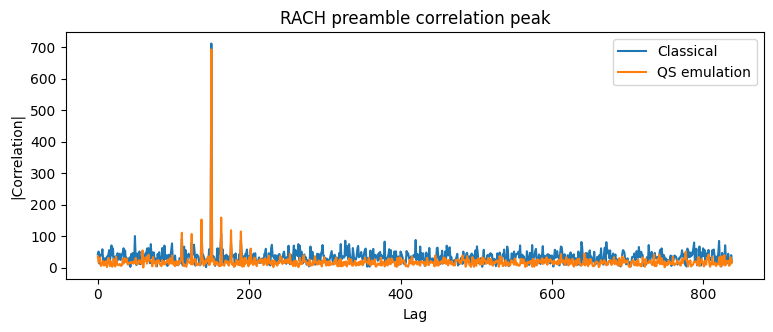

Peak(C) vs Peak(QS): 712.2682702252627 693.4099226085636
Detected offsets (C, QS): 150 150  | True: 150


In [5]:

Nzc = 839  # typical LTE/NR ZC length, simplified
u = 129    # root index
n = np.arange(Nzc)
preamble = np.exp(-1j*np.pi*u*n*(n+1)/Nzc)  # complex baseband

def detect_rach(s, preamble):
    # circular correlation magnitude
    S = np.fft.ifft(np.fft.fft(s, Nzc) * np.conj(np.fft.fft(preamble, Nzc)))
    return np.abs(S)

# Transmit burst with timing offset
toff = 150
burst = np.zeros(Nzc*2, dtype=complex)
burst[toff:toff+Nzc] = preamble

# Channel: add noise only (flat)
snr_db = -5
sig_power = np.mean(np.abs(burst)**2)
noise_std = np.sqrt(sig_power*10**(-snr_db/10)/2)

# Classical vs QS
rho = 10**(6/20)
y_c = burst + (np.random.normal(0, noise_std, size=burst.size) + 1j*np.random.normal(0, noise_std, size=burst.size))
y_q = burst + (np.random.normal(0, noise_std/rho, size=burst.size) + 1j*np.random.normal(0, noise_std/rho, size=burst.size))

# Correlation
R_c = detect_rach(y_c, preamble)
R_q = detect_rach(y_q, preamble)

plt.figure(figsize=(9,3.2))
plt.plot(R_c, label="Classical")
plt.plot(R_q, label="QS emulation")
plt.xlabel("Lag"); plt.ylabel("|Correlation|")
plt.title("RACH preamble correlation peak")
plt.legend(); plt.show()

print("Peak(C) vs Peak(QS):", float(np.max(R_c)), float(np.max(R_q)))
det_c = np.argmax(R_c); det_q = np.argmax(R_q)
print("Detected offsets (C, QS):", det_c, det_q, " | True:", toff)
